In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [4]:
import warnings
warnings.filterwarnings('ignore')

import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from load_everything import *
from harness import *
import pickle

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )

from f2_utils import *
import time_in_each_roi
import matplotlib.patches as patches
import time_in_each_roi
from sklearn.linear_model import MultiTaskLassoCV,LassoCV
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.model_selection import train_test_split


In [5]:
# prefix = '/mnt/staging/' # or '/scratch/' for s1n3/4
prefix = '/scratch/'
config_root =  str(STEPS / "step_0") + "/"
neural_root = str(STEPS / "step_2") + "/"

rotary_root = '/home/wx2203/RS_analysis/H_b_new/'

whisk_dlc_root = '/home/wx2203/Weihao/analysis/DLC/'
groom_dlc_root = '/home/wx2203/Weihao/behavior_locker/body_dlc/'
mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'

save_path = str(PREPARES / "modeling") + "/"
mouse='cm125'

In [6]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def DLC_column_correction(df,mouse):
    if mouse=='cm128':
        df.columns = pd.MultiIndex.from_tuples(
            [(   'RFP',          'x'),
                    (  'RFP',          'y'),
                    (  'RFP', 'likelihood'),
                    (   'LFP',          'x'),
                    (   'LFP',          'y'),
                    (  'LFP', 'likelihood')])
    else:
        df.columns = pd.MultiIndex.from_tuples(
                [('LFP',          'x'),
                        ('LFP',          'y'),
                        (  'LFP', 'likelihood'),
                        (    'RFP',          'x'),
                        (   'RFP',          'y'),
                        (  'RFP', 'likelihood')])
    return df

In [7]:
mouse='cm125'

In [11]:
def load_everything_new(files_list,num_regions):

    data_joint = pd.DataFrame()

    for i_file,fname in enumerate(files_list): # H file in behavior2
        f = h5py.File(fname,'r')
        ################################### identity 
        run_name = fname[-15:-4]
        mouse = fname[-25:-20]
        day = fname[-19:-18]
        mouse_day = mouse+'_'+day
        run = fname[-15:-11]
        all_bev_df = pd.DataFrame()       

        try:
            with h5py.File(pjoin(neural_root,mouse,day,'H_'+run+'_stim_1.mat'),'r') as f_H: 

                H = np.array(f_H['H']).transpose() #(36,11975)
                H = H[:,500:-505]

        except:
            print('missing',mouse,day,'H_'+run+'_stim_1.mat')
            continue
            
        try:
            with h5py.File(rotary_root+mouse_day+'_'+run+'_H.mat','r') as f_rot:
                
                rotf = pd.DataFrame((f_rot['rotf'])).rolling(window=20,axis=0).std()
                rotf = rotf.iloc[500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming   
                rotf = stats.zscore(rotf)
                rotf[rotf>3]=np.nan;
                rotf=np.array(rotf.interpolate().fillna(3))
        except:
            print('rotf missing',mouse,day,run+'_stim_1.mat')
            continue          
            
        # whisk DLC
#         f_name_dlc = glob.glob(whisk_dlc_root+'face/' + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
#         Dataframe = pd.read_hdf(f_name_dlc)
#         scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
#         new_df = Dataframe[scorer] # de-level
#         bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
#         prominent_whiskers=bodyparts[7:] #plot most prominent whiskers

#         vel_df = pd.DataFrame()
#         for i_bpt,bpt in enumerate(prominent_whiskers):
#             vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
#             vel_df[bpt] = vel
#         mean_vel = vel_df.mean(axis=1)
#         smooth_mean_vel = mean_vel.rolling(15).std()
#         smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
#         whisk_vel = smooth_mean_vel_ds[500:-505]
#         #
#         nose_pts=bodyparts[:7]
#         nose_vel_df = pd.DataFrame()
#         for i_bpt,bpt in enumerate(nose_pts):
#             vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
#             nose_vel_df[bpt] = vel
#         mean_nose_vel = nose_vel_df.mean(axis=1)
#         smooth_mean_nose_vel = mean_nose_vel.rolling(15).std() # smooth
#         smooth_mean_nose_vel_ds = np.mean(smooth_mean_nose_vel[:-1].values.reshape((-1,3)),axis=1)
#         nose_vel = smooth_mean_nose_vel_ds[500:-505]

        
        with(h5py.File(pjoin('/home/wx2203/RS_analysis/behavior',
                             mouse,day,run+'_cam_pc.mat'),'r')) as f_b:
            motionS = f_b['motionS']# this is the HDF5 reference
            motion_pc = {key: [] for key in list(motionS.keys())} 
            for key in list(motionS.keys()):

                motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
                # (200,T)
                ss=motion_pc[key].shape
                # tocut = ss[1]%4
                # if tocut ==0:
                #     motion_pc[key] = np.mean(motion_pc[key].values.reshape((ss[0],int(ss[1]/4),4)),axis=2)
                # else:
                #     motion_pc[key] = np.mean(motion_pc[key].iloc[:,:-tocut].values.reshape((ss[0],-1,4)),axis=2)

                motion_pc[key] = pd.DataFrame(motion_pc[key]).rolling(window=10,axis=1).std()
                motion_pc[key]=motion_pc[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

        face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
        face_pc = stats.zscore(face_pc)
        face_pc[face_pc>3]=np.nan;
        face_pc=np.array(face_pc.interpolate())
        
        
        #paw DLC
        paws_vel_df = pd.DataFrame();paws_vel_no_ds_df = pd.DataFrame()
        f_name_dlc = glob.glob(groom_dlc_root +mouse+'/'+ mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] 
        new_df = Dataframe[scorer] # de-level
        new_df = DLC_column_correction(new_df,mouse) # correct columns that have been mislabeled
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        for i_bpt,bpt in enumerate(bodyparts):
            p_value = new_df[bpt]['likelihood']
            filt = p_value<0.07; filt[0]=False # make sure the first frame is not NAN for being able to interpolate
            new_df[bpt]['x'][filt]=np.nan
            new_df[bpt]['y'][filt]=np.nan
            new_df[bpt] = new_df[bpt].interpolate()

            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel).rolling(15).std()
            paws_vel_no_ds_df[bpt] = np.squeeze(stats.zscore(vel,nan_policy='omit'))
            vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = stats.zscore(vel[500:-505])
            vel_ds = paws_vel_df[bpt].copy()
            vel_ds[vel_ds>3]=np.nan;
            paws_vel_df[bpt]=vel_ds
            paws_vel_df[bpt]=np.array(paws_vel_df[bpt].interpolate())


        f_config = h5py.File(config_root+'groom_config_'+mouse+'.mat','r')
        x_top_left = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,0]
        x_botton_right = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,1]
        y_top_left = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,0]
        y_botton_right = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,1]
        out_h = int((x_botton_right - x_top_left)/3)
        out_w = int((y_botton_right - y_top_left)/3) + 50
        y = int(x_top_left/3)
        x = int(y_top_left/3)-50 # wider
        fig = plt.figure(figsize=(15,4))
        ax = fig.add_subplot(121)
        plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
        plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
        import matplotlib.patches as patches
        rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
        plt.ylim([0,400]);plt.legend();ax.add_patch(rect);plt.gca().invert_yaxis()
        is_LFP_in = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
        # is_LFP_move = paws_vel_no_ds_df['LFP']>0.1
        is_RFP_in = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)

        is_groom = np.logical_and(is_LFP_in,is_RFP_in)
        is_groom_smooth = is_groom.rolling(60).mean()
        is_groom_smooth_ds = np.mean(is_groom_smooth[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

        ax2 = fig.add_subplot(122)
        plt.plot(normalize(face_pc)+3,label='face_pc')
        plt.plot(is_groom_smooth_ds+2,label='is_groom')
        plt.plot(normalize(paws_vel_df['LFP'])+1,label='LFP vel')
        # plt.plot(normalize(nose_vel)-1,label='nose vel')
#         plt.plot(normalize(face_pc)-1,label='face PC')
        plt.plot(normalize(rotf)-1,label='rotary encoder')
        # plt.plot(pupil_p_value-2,label='pupil P value')
        plt.title(mouse_day+'_'+run_name)
        # plt.legend(fontsize = 10)
        ax2.legend(loc='upper center', bbox_to_anchor=(1.5, 1.05),
          ncol=1, fancybox=True, shadow=True)

        # with h5py.File(pjoin(neural_root,mouse,day,'H_'+run+'_stim_1.mat'),'r') as f_H: 
        #     H = np.array(f_H['H']).transpose() #(num_regions,11980)
        #     H = stats.zscore(H[:,500:-505],axis=1)#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming         

        all_bev_df['face_pc'] = face_pc
#         all_bev_df['face_pc'] = face_pc
        all_bev_df['rotf'] = rotf
        all_bev_df['is_groom'] = is_groom_smooth_ds        
        paws_vel_df.drop('RFP', inplace=True, axis=1)
        all_bev_df = all_bev_df.join(paws_vel_df)

        data_pot = pd.concat([pd.DataFrame(H).transpose(),all_bev_df],names=['column_level'],axis=1)
        data_pot = pd.concat([data_pot], keys=[mouse_day+'_'+run], names=['row_level'])
        data_joint = data_joint.append(data_pot)
        print(mouse_day,run,data_joint.shape)


    return data_joint

In [12]:
if mouse=='cm125':
    f1 = list(set(glob.glob(neural_root+"*125/[1-3]/H_run[B-J]*.mat"))-
             set(glob.glob(neural_root+"*125/1/H_runH*.mat")))

    files_list = f1

files_list

['/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/1/H_runE_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/1/H_runF_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/2/H_runJ_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/2/H_runH_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/2/H_runI_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/2/H_runB_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/1/H_runI_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/3/H_runG_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/1/H_runD_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125/2/H_runC_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm125

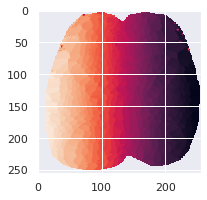

In [13]:
with h5py.File(config_root+'idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.figure(figsize=(3,3))
plt.imshow(IDX_sorted)



cm125_1 runE (10975, 504)
cm125_1 runF (21950, 504)
cm125_2 runJ (32925, 504)
cm125_2 runH (43900, 504)
cm125_2 runI (54875, 504)
cm125_2 runB (65850, 504)
cm125_1 runI (76825, 504)
cm125_3 runG (87800, 504)
cm125_1 runD (98775, 504)
cm125_2 runC (109750, 504)
cm125_3 runC (120725, 504)
cm125_1 runC (131700, 504)
cm125_1 runJ (142675, 504)
cm125_3 runD (153650, 504)
cm125_3 runF (164625, 504)
cm125_3 runE (175600, 504)
cm125_2 runF (186575, 504)
cm125_2 runD (197550, 504)
cm125_1 runB (208525, 504)
cm125_3 runI (219500, 504)
cm125_3 runJ (230475, 504)
cm125_1 runG (241450, 504)
cm125_2 runG (252425, 504)
cm125_2 runE (263400, 504)
cm125_3 runB (274375, 504)
cm125_3 runH (285350, 504)


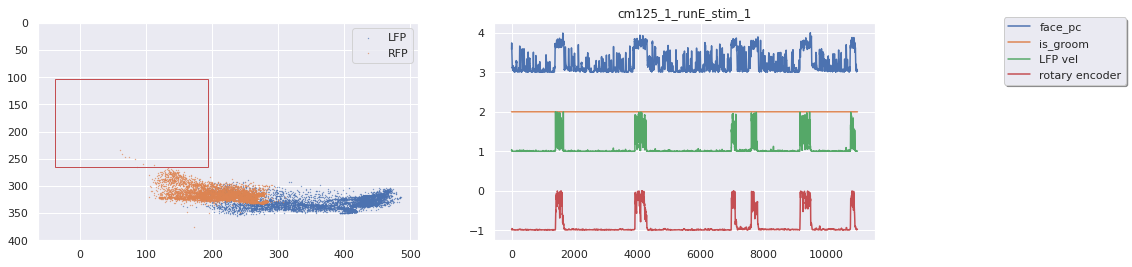

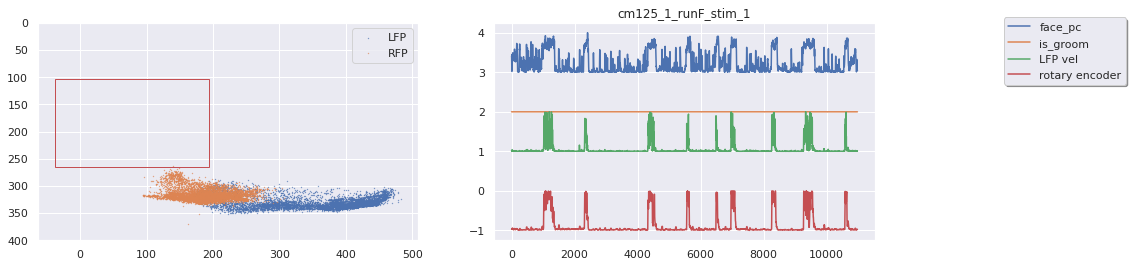

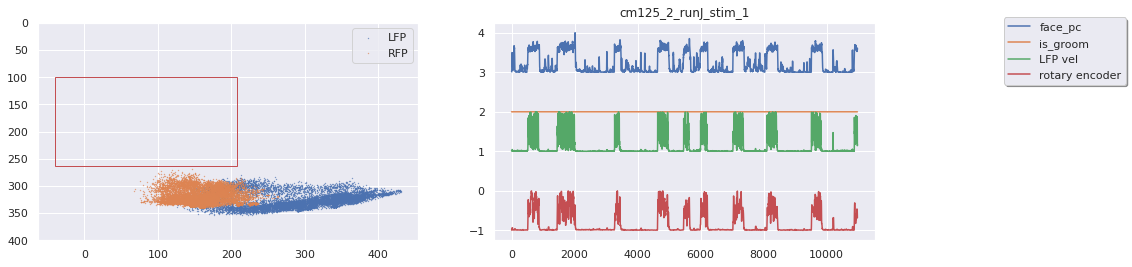

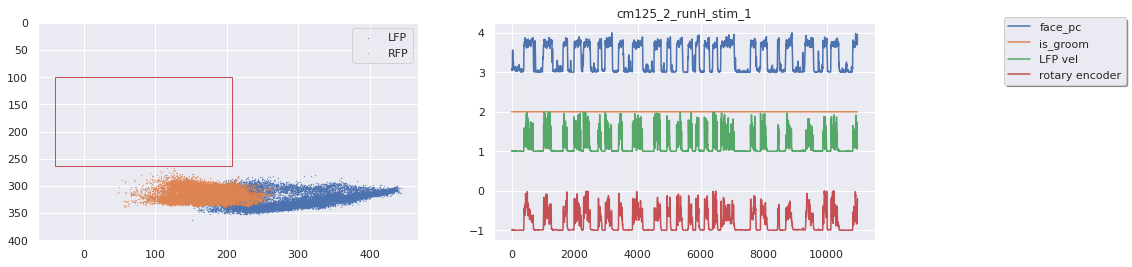

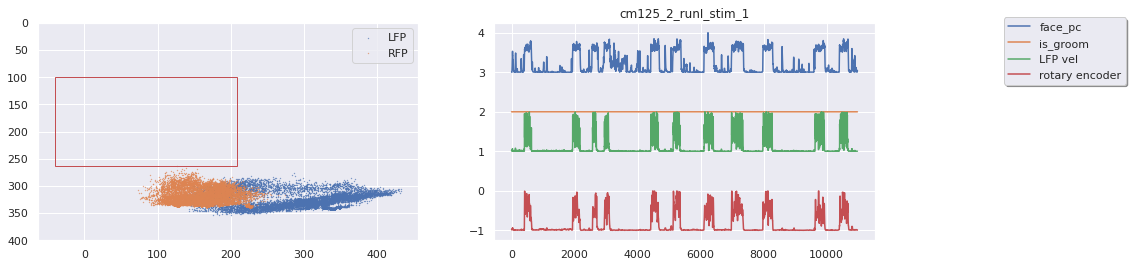

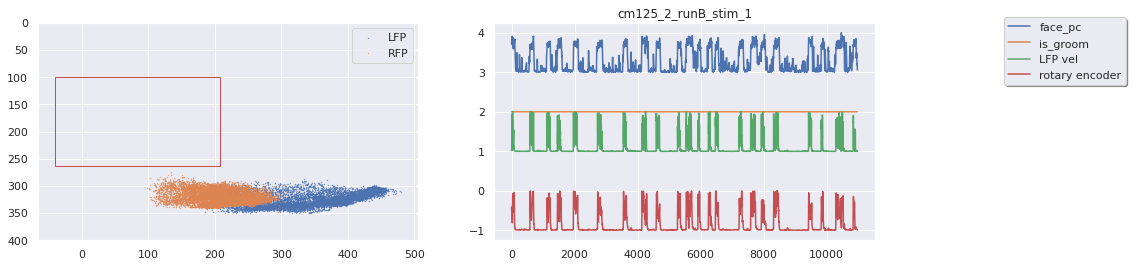

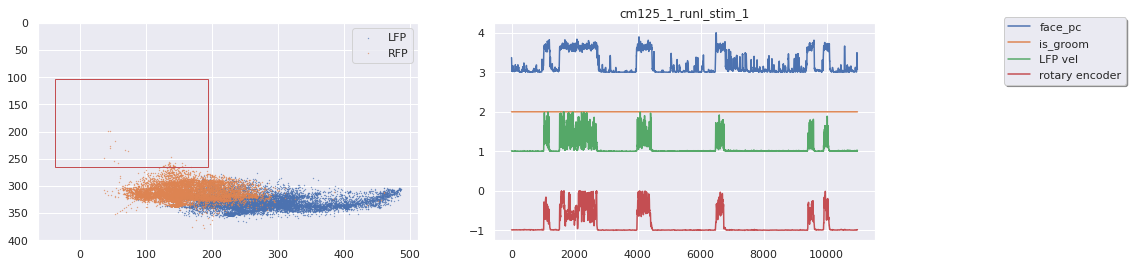

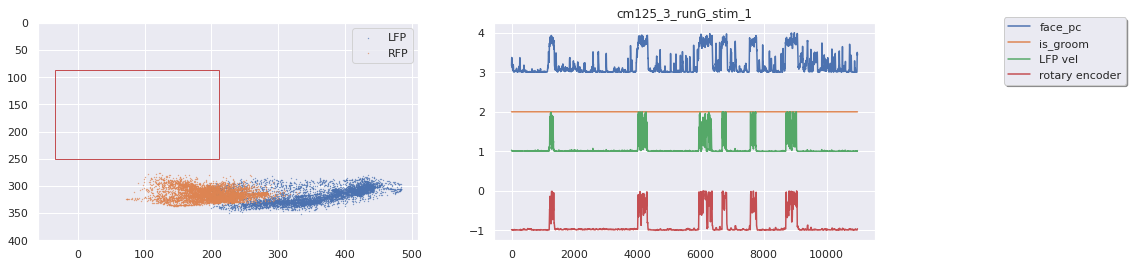

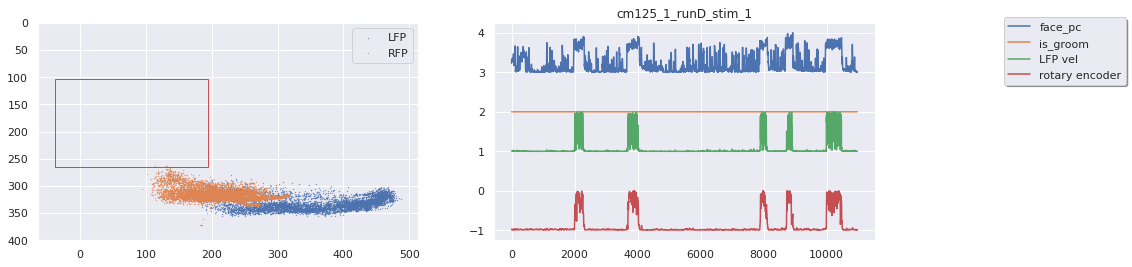

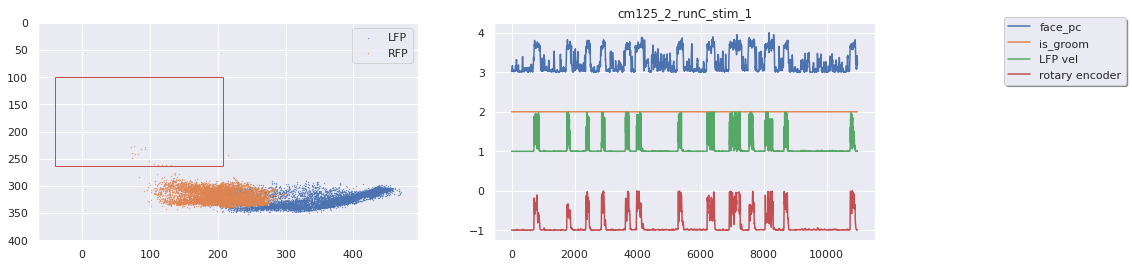

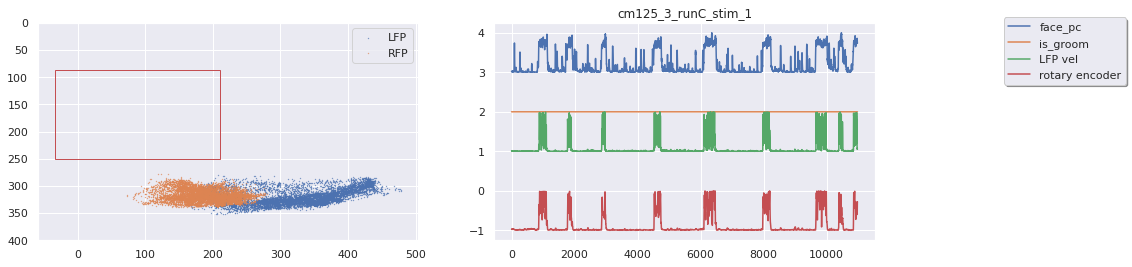

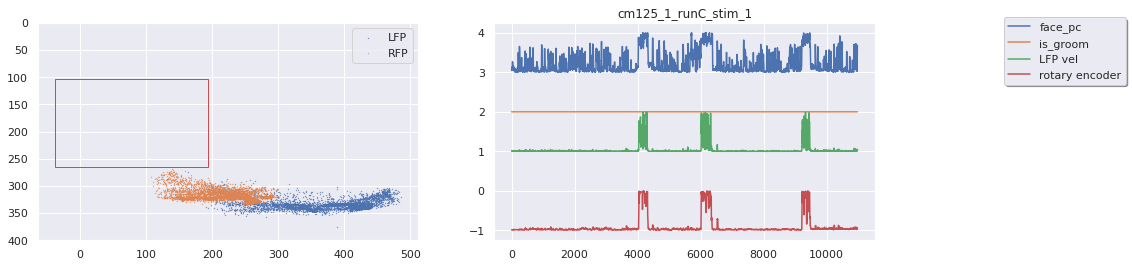

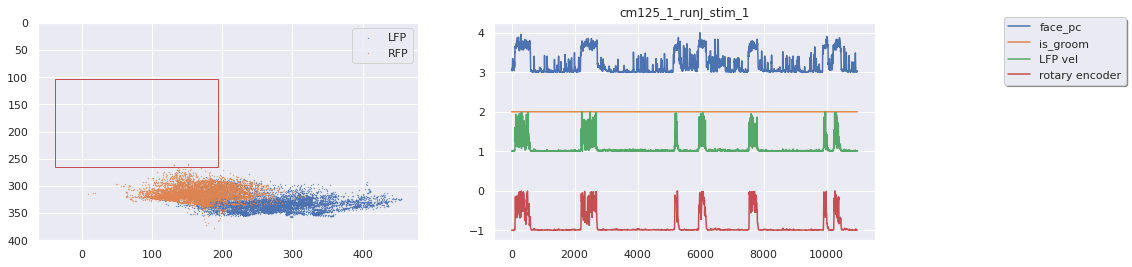

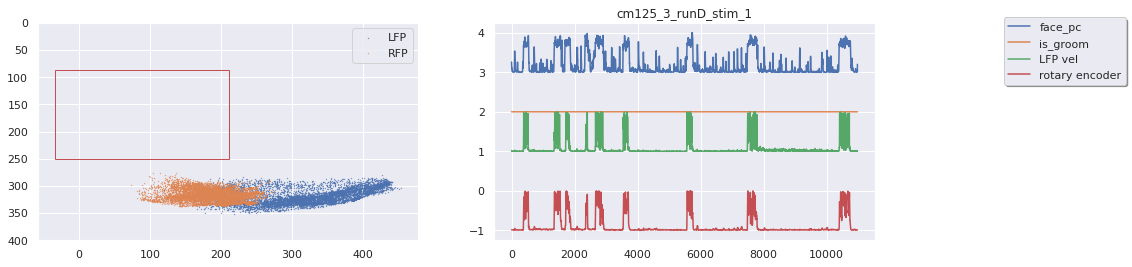

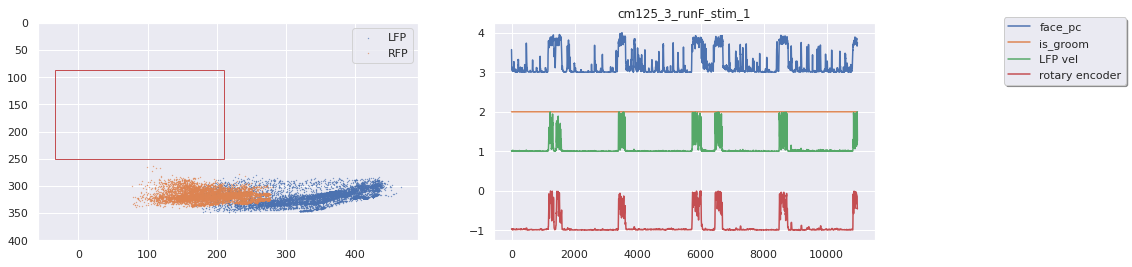

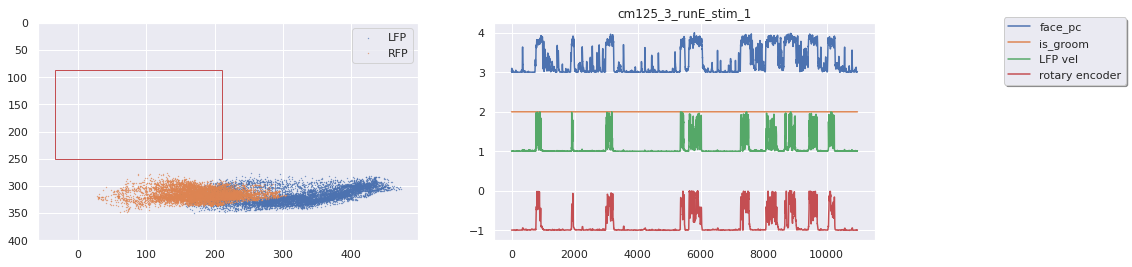

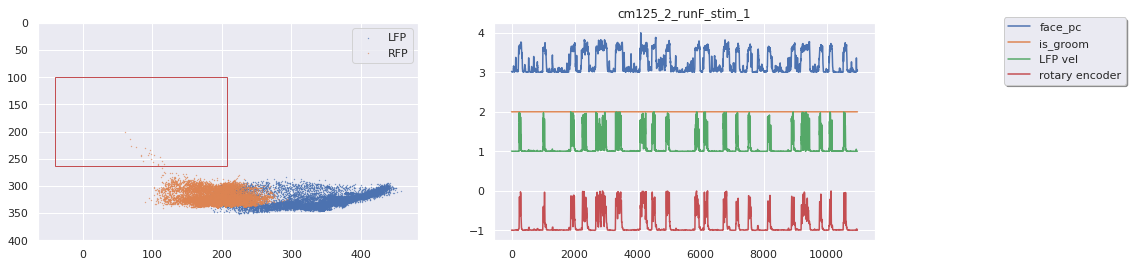

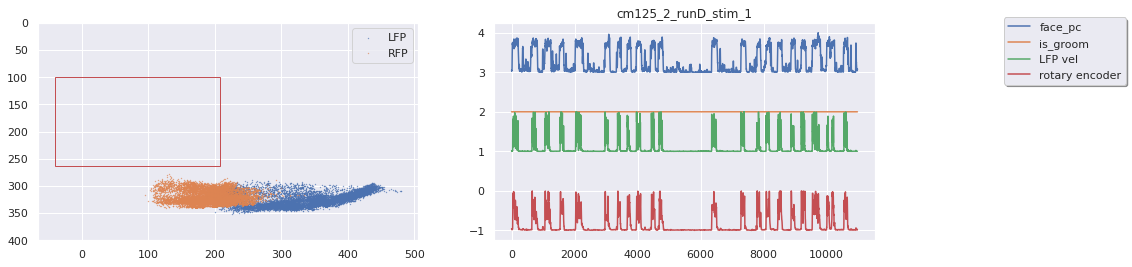

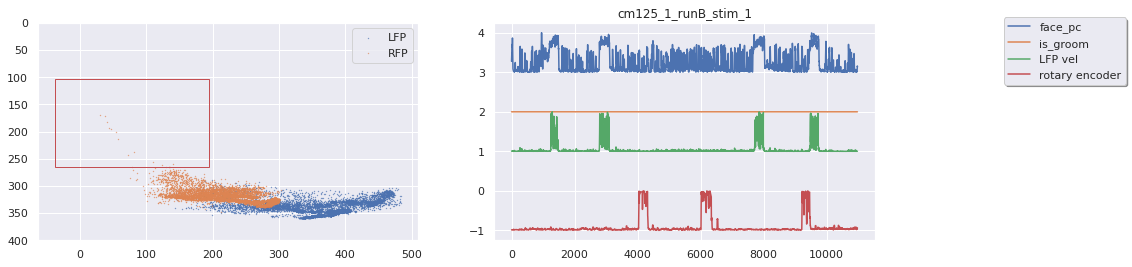

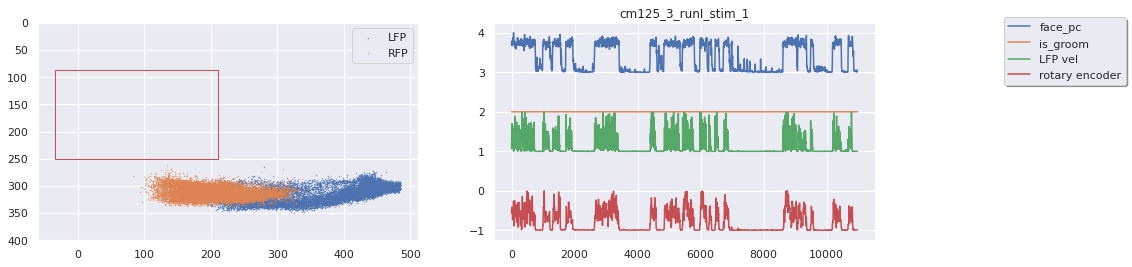

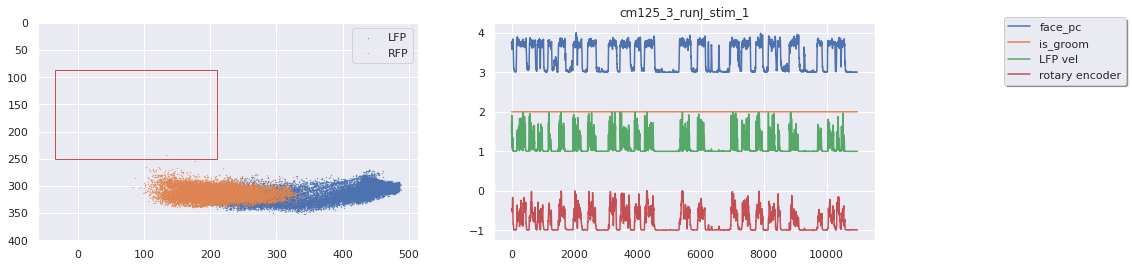

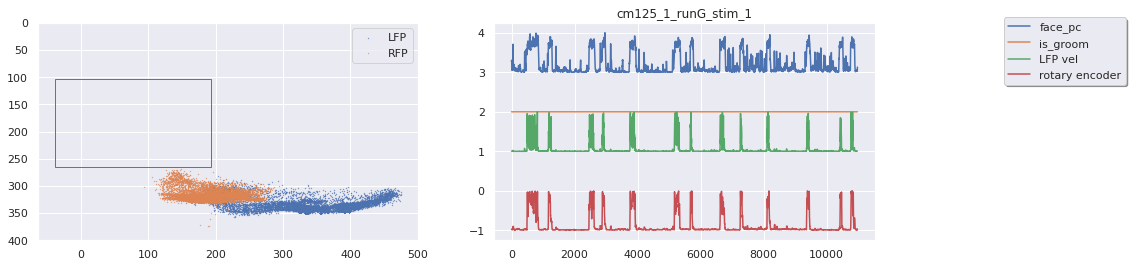

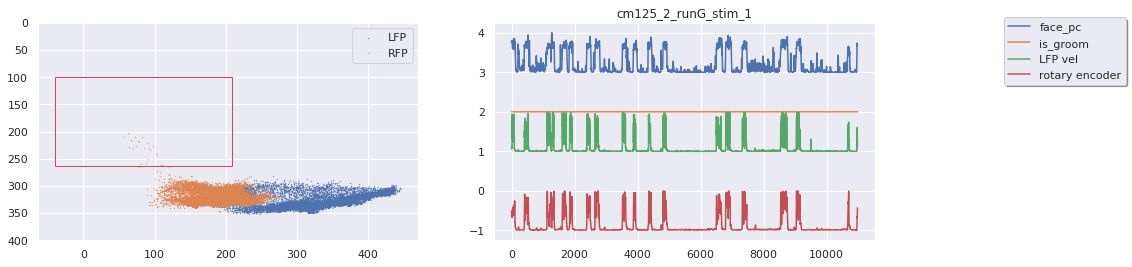

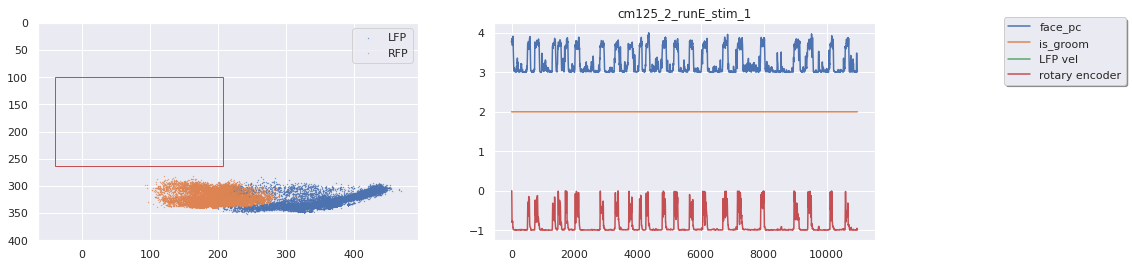

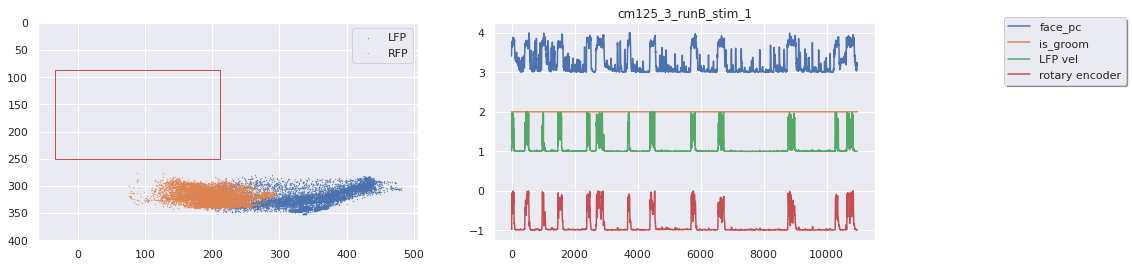

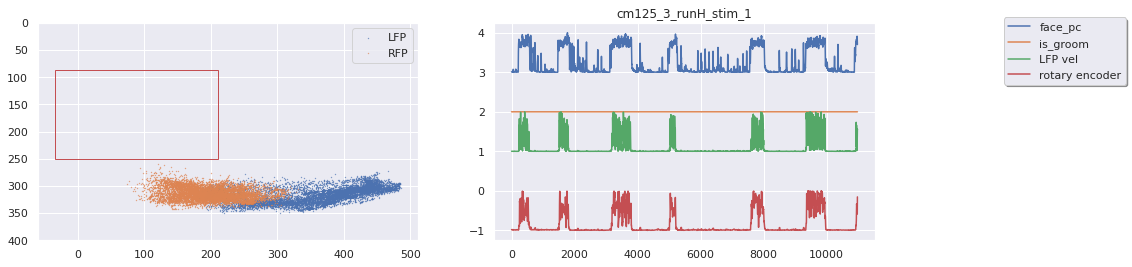

In [14]:
data_joint = load_everything_new(files_list,500)
save_model(data_joint,save_path+mouse+'_data_joint.pickle')


In [15]:
np.argwhere(np.isnan(data_joint.values))

array([[252425,    503]])

In [16]:
data_joint=data_joint.fillna(3)
np.argwhere(np.isnan(data_joint.values))

array([], shape=(0, 2), dtype=int64)

In [17]:
save_model(data_joint,save_path+mouse+'_data_joint.pickle')


In [15]:
save_path

'/scratch/users/wx2203/new_analysis_locker/pub-locker/modeling/'

obsolete:

# Linear model (sensory v.s. motor)

In [ ]:
def get_data_split(X,Y,train_size_value=0.6):
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=train_size_value,shuffle=True,
                                                       random_state=7)
    dataDict ={'X_train':X_train,
              'X_test':X_test,
              'Y_train':Y_train,
              'Y_test':Y_test}
    print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
    return dataDict

In [17]:
def fit_multi_linear_model(X_train,Y_train):
    LCV = MultiTaskLassoCV(alphas=[1e-4, 5e-4, 8e-4,1e-3, 2e-3, 5e-3, 1e-2],cv=5,n_jobs=-1).fit(X_train, Y_train)
    return LCV
def fit_uni_linear_model(X_train,Y_train):
    LCV = LassoCV(alphas=[1e-4, 5e-4, 8e-4,1e-3, 2e-3, 5e-3, 1e-2],cv=5,n_jobs=-1,tol=1e-9).fit(X_train, Y_train)
    return LCV

In [18]:
motorDict = get_data_split(H_motor_cat,np.hstack((data_joint['whisk_vel'].values,data_joint['LFP'].values)))

/home/wx2203/anaconda3/lib/python3.7/site-packages/sklearn/model_selection/_split.py:2179: FutureWarning: From version 0.21, test_size will always complement train_size unless both are specified.
  FutureWarning)


(206640, 140) (137760, 140) (206640, 2) (137760, 2)


In [19]:
np.argwhere(np.isnan(data_joint.values))

array([], shape=(0, 2), dtype=int64)

In [23]:
face_motorLassoModel = fit_uni_linear_model(motorDict['X_train'],motorDict['Y_train'][:,0])
body_motorLassoModel = fit_uni_linear_model(motorDict['X_train'],motorDict['Y_train'][:,1])

In [24]:
save_model(face_motorLassoModel,f4_locker_root+mouse+'win_'+str(win_width)+'_face_motorLassoModel')
save_model(body_motorLassoModel,f4_locker_root+mouse+'win_'+str(win_width)+'_body_motorLassoModel')

In [19]:
face_motorLassoModel = load_model(f4_locker_root+mouse+'win_'+str(win_width)+'_face_motorLassoModel')
body_motorLassoModel = load_model(f4_locker_root+mouse+'win_'+str(win_width)+'_body_motorLassoModel')

# hi

In [26]:
run_names = data_joint.index.get_level_values(0).drop_duplicates()
score_table = pd.DataFrame()
for i_run, runname in enumerate(run_names):
    face_score = face_motorLassoModel.score(data_joint.loc[runname]['H'].iloc[:,motor_region_ind==1],data_joint.loc[runname]['face_pc'])
    body_score = body_motorLassoModel.score(data_joint.loc[runname]['H'].iloc[:,motor_region_ind==1],data_joint.loc[runname]['body_pc'])
    
    score_pd = pd.DataFrame({'face_score':[face_score],'body_score':[body_score]})
    score_pd = pd.concat([score_pd], keys=[runname], names=['row_level'])
    score_table = score_table.append(score_pd)

In [40]:
score_table

,,face_score,body_score
row_level,,,
cm125_1_runI,0,0.342101,0.337126
cm125_1_runG,0,0.614003,0.681002
cm125_1_runJ,0,0.383778,0.516967
cm125_1_runE,0,0.494641,0.527610
cm125_1_runC,0,0.452941,0.465381
cm125_1_runD,0,0.426915,0.472772
cm125_1_runF,0,0.540679,0.619474
cm125_2_runH,0,0.747096,0.730893
cm125_2_runB,0,0.668855,0.783831


In [42]:
save_model(score_table,'/home/wx2203/Weihao/analysis_locker/f4/'+mouse+'_linear_score_table.pickle')



In [1]:
runname = 'cm125_4_runC'

face_pred = face_motorLassoModel.predict(data_joint.loc[runname]['H_std'].iloc[:,motor_region_ind==1])
body_pred = body_motorLassoModel.predict(data_joint.loc[runname]['H_std'].iloc[:,motor_region_ind==1])

face_real=data_joint.loc[runname]['whisk_vel']
body_real=data_joint.loc[runname]['LFP']


/home/wx2203/anaconda3/lib/python3.7/site-packages/dask/dataframe/utils.py:13: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


NameError: name 'face_motorLassoModel' is not defined

In [ ]:
plt.figure(figsize=(20,15))
time_range=range(3000)
plt.subplot(211)
plt.plot(face_real.values[time_range],label='face_real')
plt.plot(face_pred[time_range],label='face pred')

plt.subplot(212)
plt.plot(body_real.values[time_range],label='body real')
plt.plot(body_pred[time_range],label='body pred')
